# 18 — Five-label GLiNER extraction across every fit pair

Report the saved campaign covering **both processed fit splits**, with each unique CV/JD extracted once and its predictions attached to every original pair. This notebook loads saved results only; executing it never launches or resumes expensive inference.

The approved [campaign plan](../plan/2026-10-14-fit-pair-gliner-comparison/README.md) freezes KNOWLEDGE, SKILL, TITLE, DEGREE and EXPERIENCE_YEARS, threshold 0.5, pinned local GLiNER and its chunk policy. Five requested categories do not force five extracted entities.

This is an **A1 training resource / secondary benchmark whose labels do not reproduce (A13)**. Fit-conditioned summaries below are exploratory descriptions of extraction outputs, not extraction accuracy, a new matching score or final-set tuning. Fit labels do not supply entity gold spans.

In [29]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
from candidate_screener.config import OUTPUT
from candidate_screener.annotation.redact import assert_clean, redact_text
from candidate_screener.extraction.fit_run import load_campaign, report_tables, examples
from candidate_screener.extraction.fit_plots import save_fit_charts, example_counts, pair_mentions

# Read the saved frozen campaign. No run_campaign/model call belongs here.
REPORT_DIRECTORY = OUTPUT / "extraction" / "fit-comparison"


def show_summary(value):
    rendered = json.dumps(value, indent=2, default=str, ensure_ascii=False)
    print(rendered if len(rendered) <= 1900 else rendered[:1850] + "\n[output truncated]")


## Campaign identity, population and completion

Read source/configuration provenance and completion before any distribution. A completed document with no spans is a measured zero; an incomplete, failed or pending document is an unavailable result. These states must not be merged into zero. Predictions preserve exact half-open offsets into immutable full text.

CVs and JDs can recur across pairs. Unique-document charts count each once within the relevant split; pair summaries attach those same records to each original pair.

In [35]:
campaign = load_campaign()
tables = report_tables(campaign)
show_summary(campaign["summary"])



{
  "requested_documents": 949,
  "states": {
    "complete": 913,
    "complete_zero": 36
  },
  "entities": 13946,
  "runtime_seconds": 2012.7189738036832
}


In [34]:
# campaign = load_campaign('901a26c9e785920223b07c9b')
# tables = report_tables(campaign)
# show_summary(campaign["summary"])


In [36]:
show_summary(campaign["metadata"]["inventory"])
show_summary({"campaign_id": campaign["metadata"]["campaign_id"],
              "threshold": campaign["metadata"]["provenance"]["threshold"],
              "labels": campaign["metadata"]["provenance"]["labels"]})


{
  "test": {
    "cvs": 158,
    "jds": 100,
    "pairs": 659
  },
  "total": {
    "characters": 4551699,
    "pairs": 4649,
    "unique_documents": 949
  },
  "train": {
    "cvs": 446,
    "jds": 245,
    "pairs": 3990
  }
}
{
  "campaign_id": "901a26c9e785920223b07c9b",
  "threshold": 0.5,
  "labels": {
    "academic degree or qualification": "DEGREE",
    "job title or occupation": "TITLE",
    "professional skill or competency": "SKILL",
    "technology, software tool or programming language": "KNOWLEDGE",
    "years of experience": "EXPERIENCE_YEARS"
  }
}


In [37]:
provenance = campaign["metadata"]["provenance"]
show_summary({"checkpoint": {key: provenance["model"][key] for key in ("model_id", "revision")}, "source_sha256": provenance["source_sha256"], "budget_seconds_per_document": provenance["per_document_seconds"], "budget_policy": "Soft deadline checked between chunks; an active model call is not preempted"})


{
  "checkpoint": {
    "model_id": "urchade/gliner_small-v2.1",
    "revision": "4e091416cf7c3481db542c2a3d26156916f3a47f"
  },
  "source_sha256": {
    "test": "913cda27961604fe92fff1ba9adbec3b2beb27fc8377bfaeeb74aea2e796c1b1",
    "train": "b8a0cbeb5ce2307bfdfa12243f0e351ab29a58807424ca78873f201744fabbc7"
  },
  "budget_seconds_per_document": 120,
  "budget_policy": "Soft deadline checked between chunks; an active model call is not preempted"
}


## Completion states and all-five-label counts

Counts reflect mention spans; repeated occurrences are distinct. Unique mentions use case-folded strings for descriptive grouping, not canonical linking. Every configured label remains visible even when its count is zero. Unknown unfinished results remain separate from completed-zero documents.

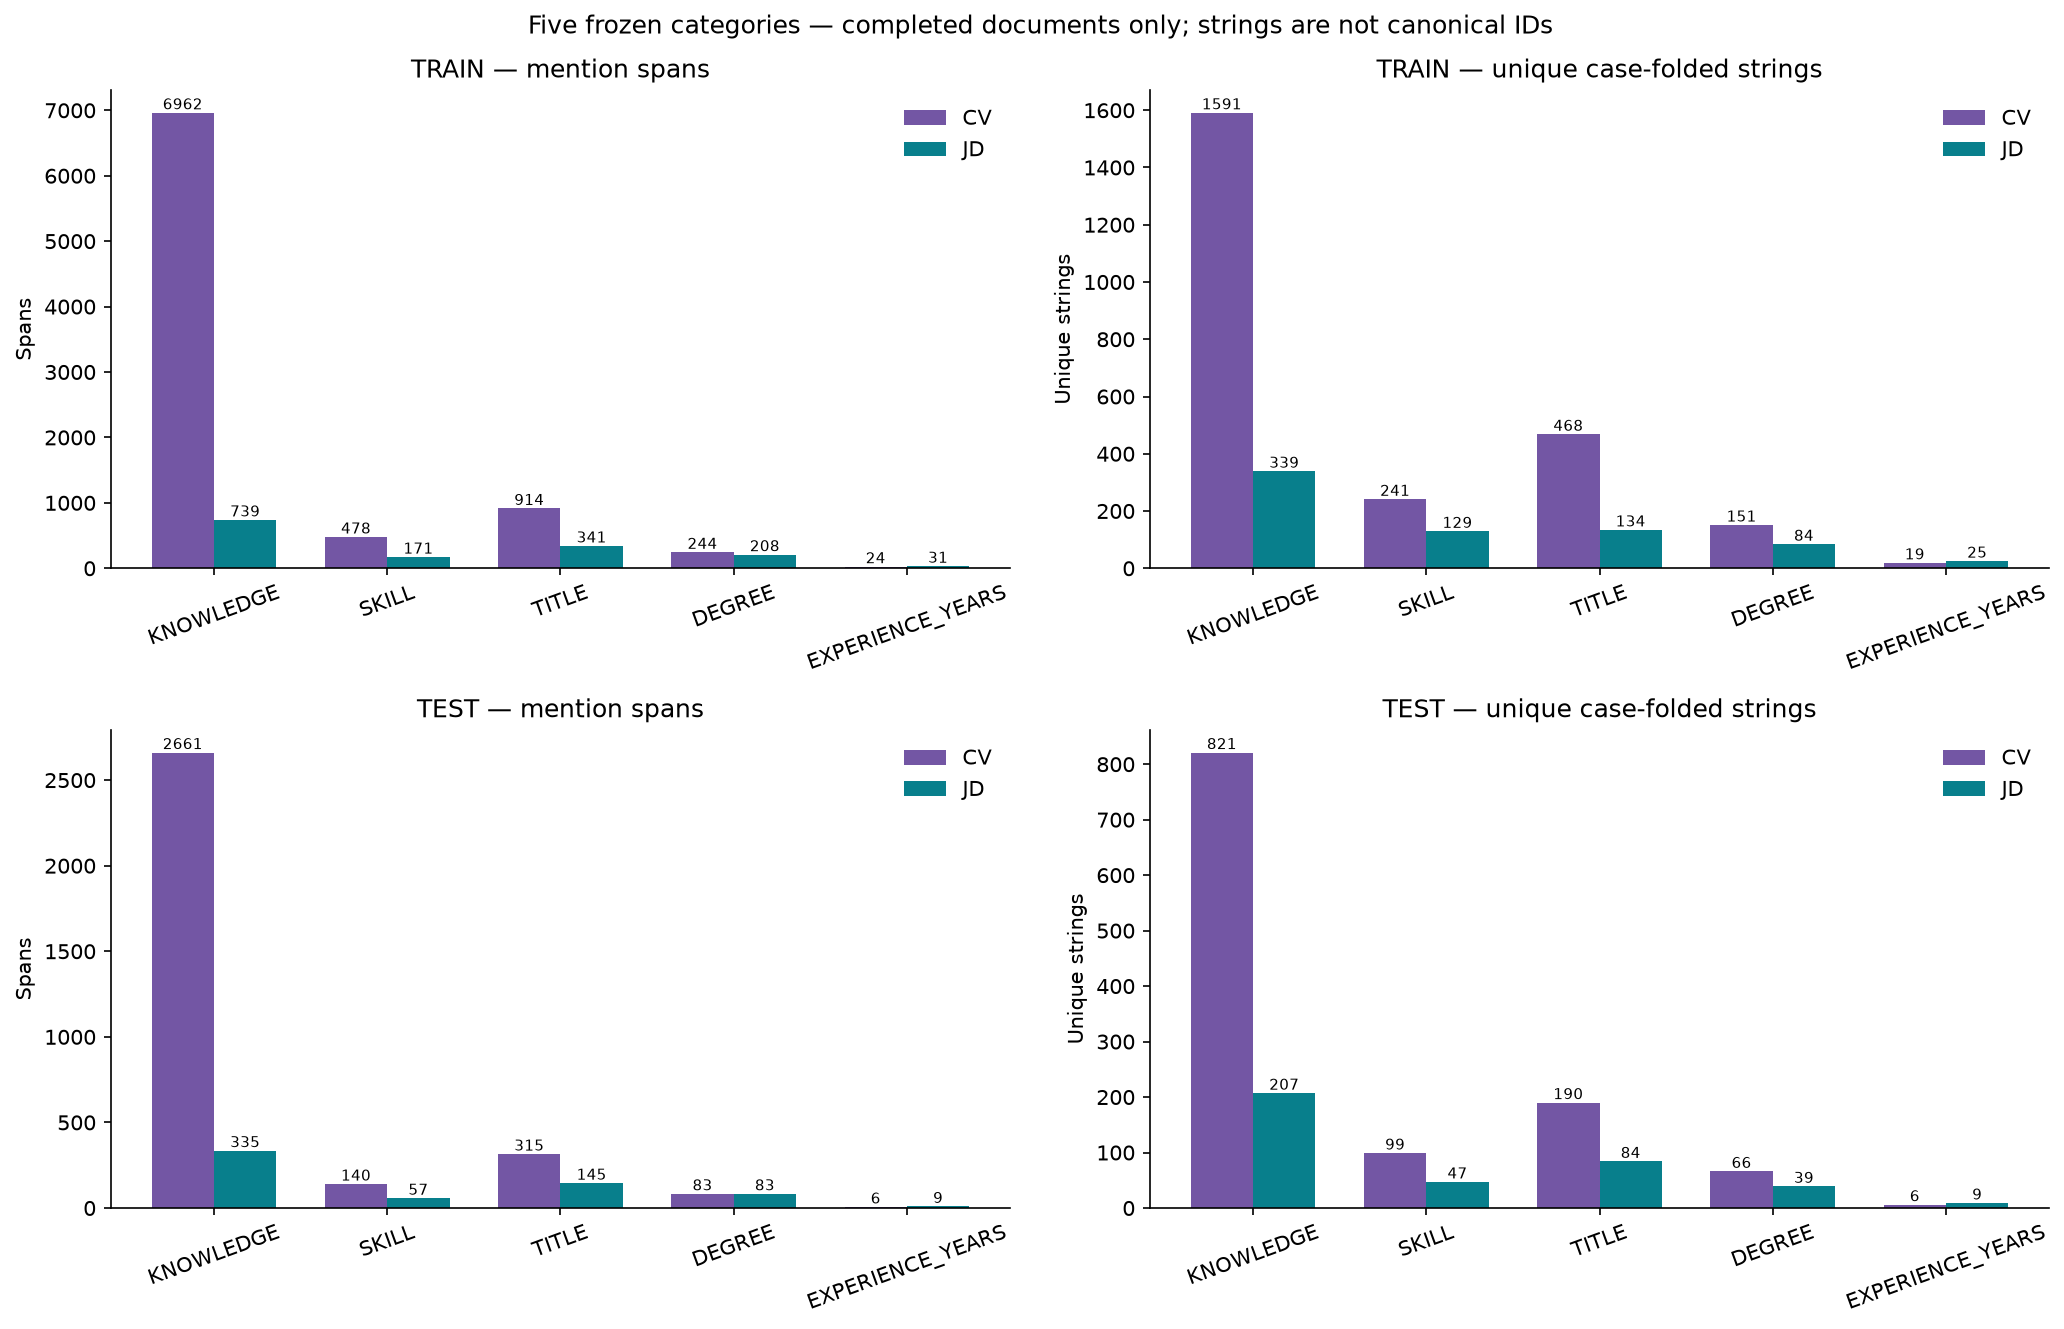

In [38]:
charts = save_fit_charts(campaign, REPORT_DIRECTORY)
display(Image(filename=charts["counts"]))


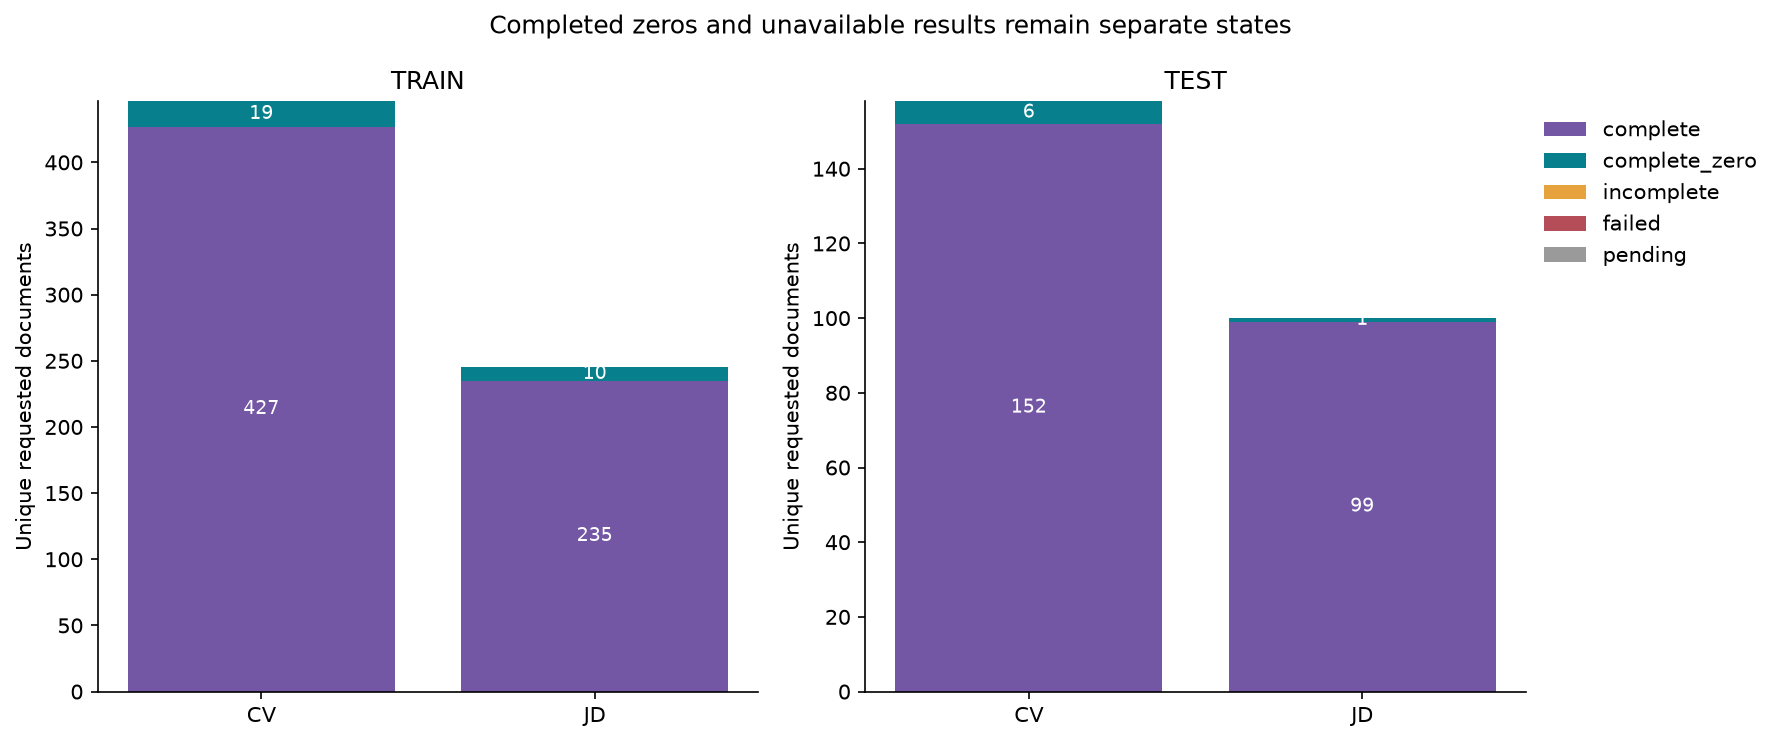

In [39]:
display(Image(filename=charts["states"]))

## Per-split label coverage

Coverage denominators include the complete requested split population; the state chart tells you whether all those documents were successfully processed. These are **descriptive extraction coverage** values, not precision or recall. The tables show five categories per side/split.

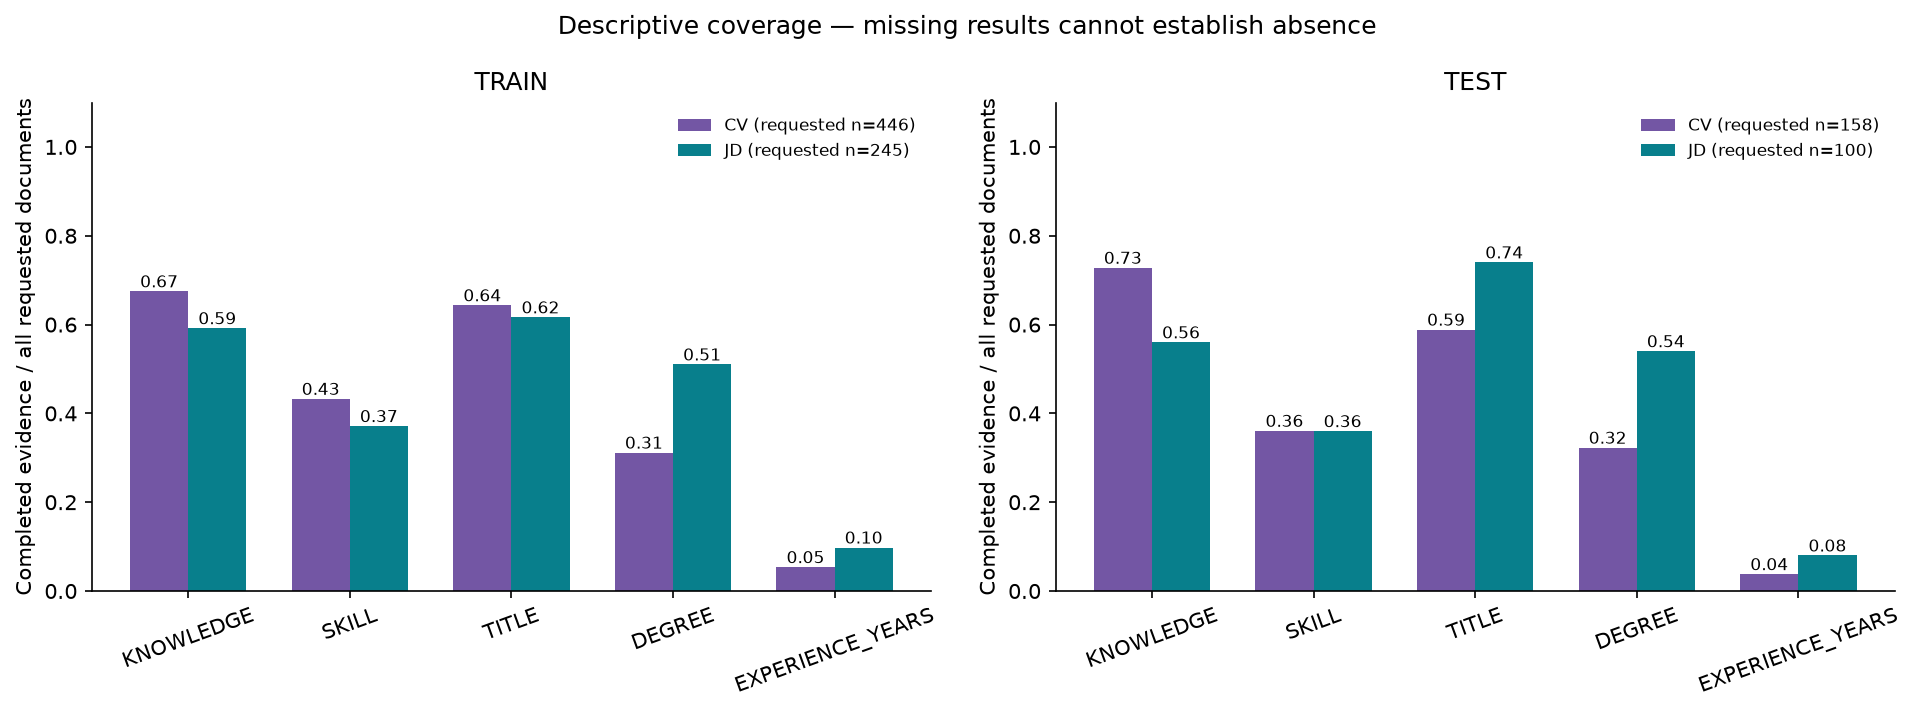

In [40]:
display(Image(filename=charts["coverage"]))

### TRAIN / CV — five-label counts and completed coverage

In [41]:
count_rows = tables["counts"].loc[(tables["counts"].split == "train") & (tables["counts"].doc_type == "cv")]
coverage_rows = tables["label_coverage"].loc[(tables["label_coverage"].split == "train") & (tables["label_coverage"].doc_type == "cv")]
preview = count_rows.merge(coverage_rows.drop(columns=["split", "doc_type"]), on="label")
rendered = preview.to_json(orient="records", force_ascii=False)
assert len(preview) <= 5 and len(rendered) <= 1990
print(rendered)


[{"split":"train","doc_type":"cv","label":"KNOWLEDGE","entities":6962,"unique_mentions":1591,"covered_documents":301,"requested_documents":446,"completed_documents":446,"operational_coverage":0.6748878924},{"split":"train","doc_type":"cv","label":"SKILL","entities":478,"unique_mentions":241,"covered_documents":193,"requested_documents":446,"completed_documents":446,"operational_coverage":0.432735426},{"split":"train","doc_type":"cv","label":"TITLE","entities":914,"unique_mentions":468,"covered_documents":287,"requested_documents":446,"completed_documents":446,"operational_coverage":0.6434977578},{"split":"train","doc_type":"cv","label":"DEGREE","entities":244,"unique_mentions":151,"covered_documents":139,"requested_documents":446,"completed_documents":446,"operational_coverage":0.3116591928},{"split":"train","doc_type":"cv","label":"EXPERIENCE_YEARS","entities":24,"unique_mentions":19,"covered_documents":24,"requested_documents":446,"completed_documents":446,"operational_coverage":0.05

### TRAIN / JD — five-label counts and completed coverage

In [42]:
count_rows = tables["counts"].loc[(tables["counts"].split == "train") & (tables["counts"].doc_type == "jd")]
coverage_rows = tables["label_coverage"].loc[(tables["label_coverage"].split == "train") & (tables["label_coverage"].doc_type == "jd")]
preview = count_rows.merge(coverage_rows.drop(columns=["split", "doc_type"]), on="label")
rendered = preview.to_json(orient="records", force_ascii=False)
assert len(preview) <= 5 and len(rendered) <= 1990
print(rendered)


[{"split":"train","doc_type":"jd","label":"KNOWLEDGE","entities":739,"unique_mentions":339,"covered_documents":145,"requested_documents":245,"completed_documents":245,"operational_coverage":0.5918367347},{"split":"train","doc_type":"jd","label":"SKILL","entities":171,"unique_mentions":129,"covered_documents":91,"requested_documents":245,"completed_documents":245,"operational_coverage":0.3714285714},{"split":"train","doc_type":"jd","label":"TITLE","entities":341,"unique_mentions":134,"covered_documents":151,"requested_documents":245,"completed_documents":245,"operational_coverage":0.6163265306},{"split":"train","doc_type":"jd","label":"DEGREE","entities":208,"unique_mentions":84,"covered_documents":125,"requested_documents":245,"completed_documents":245,"operational_coverage":0.5102040816},{"split":"train","doc_type":"jd","label":"EXPERIENCE_YEARS","entities":31,"unique_mentions":25,"covered_documents":24,"requested_documents":245,"completed_documents":245,"operational_coverage":0.09795

### TEST / CV — five-label counts and completed coverage

In [43]:
count_rows = tables["counts"].loc[(tables["counts"].split == "test") & (tables["counts"].doc_type == "cv")]
coverage_rows = tables["label_coverage"].loc[(tables["label_coverage"].split == "test") & (tables["label_coverage"].doc_type == "cv")]
preview = count_rows.merge(coverage_rows.drop(columns=["split", "doc_type"]), on="label")
rendered = preview.to_json(orient="records", force_ascii=False)
assert len(preview) <= 5 and len(rendered) <= 1990
print(rendered)


[{"split":"test","doc_type":"cv","label":"KNOWLEDGE","entities":2661,"unique_mentions":821,"covered_documents":115,"requested_documents":158,"completed_documents":158,"operational_coverage":0.7278481013},{"split":"test","doc_type":"cv","label":"SKILL","entities":140,"unique_mentions":99,"covered_documents":57,"requested_documents":158,"completed_documents":158,"operational_coverage":0.3607594937},{"split":"test","doc_type":"cv","label":"TITLE","entities":315,"unique_mentions":190,"covered_documents":93,"requested_documents":158,"completed_documents":158,"operational_coverage":0.5886075949},{"split":"test","doc_type":"cv","label":"DEGREE","entities":83,"unique_mentions":66,"covered_documents":51,"requested_documents":158,"completed_documents":158,"operational_coverage":0.3227848101},{"split":"test","doc_type":"cv","label":"EXPERIENCE_YEARS","entities":6,"unique_mentions":6,"covered_documents":6,"requested_documents":158,"completed_documents":158,"operational_coverage":0.0379746835}]


### TEST / JD — five-label counts and completed coverage

In [44]:
count_rows = tables["counts"].loc[(tables["counts"].split == "test") & (tables["counts"].doc_type == "jd")]
coverage_rows = tables["label_coverage"].loc[(tables["label_coverage"].split == "test") & (tables["label_coverage"].doc_type == "jd")]
preview = count_rows.merge(coverage_rows.drop(columns=["split", "doc_type"]), on="label")
rendered = preview.to_json(orient="records", force_ascii=False)
assert len(preview) <= 5 and len(rendered) <= 1990
print(rendered)


[{"split":"test","doc_type":"jd","label":"KNOWLEDGE","entities":335,"unique_mentions":207,"covered_documents":56,"requested_documents":100,"completed_documents":100,"operational_coverage":0.56},{"split":"test","doc_type":"jd","label":"SKILL","entities":57,"unique_mentions":47,"covered_documents":36,"requested_documents":100,"completed_documents":100,"operational_coverage":0.36},{"split":"test","doc_type":"jd","label":"TITLE","entities":145,"unique_mentions":84,"covered_documents":74,"requested_documents":100,"completed_documents":100,"operational_coverage":0.74},{"split":"test","doc_type":"jd","label":"DEGREE","entities":83,"unique_mentions":39,"covered_documents":54,"requested_documents":100,"completed_documents":100,"operational_coverage":0.54},{"split":"test","doc_type":"jd","label":"EXPERIENCE_YEARS","entities":9,"unique_mentions":9,"covered_documents":8,"requested_documents":100,"completed_documents":100,"operational_coverage":0.08}]


## Per-document distributions, including completed zeros

Only complete results enter measured count distributions. Completed-zero documents contribute zero to every label and to total span counts. Failed, incomplete and pending documents do not contribute invented zero counts.

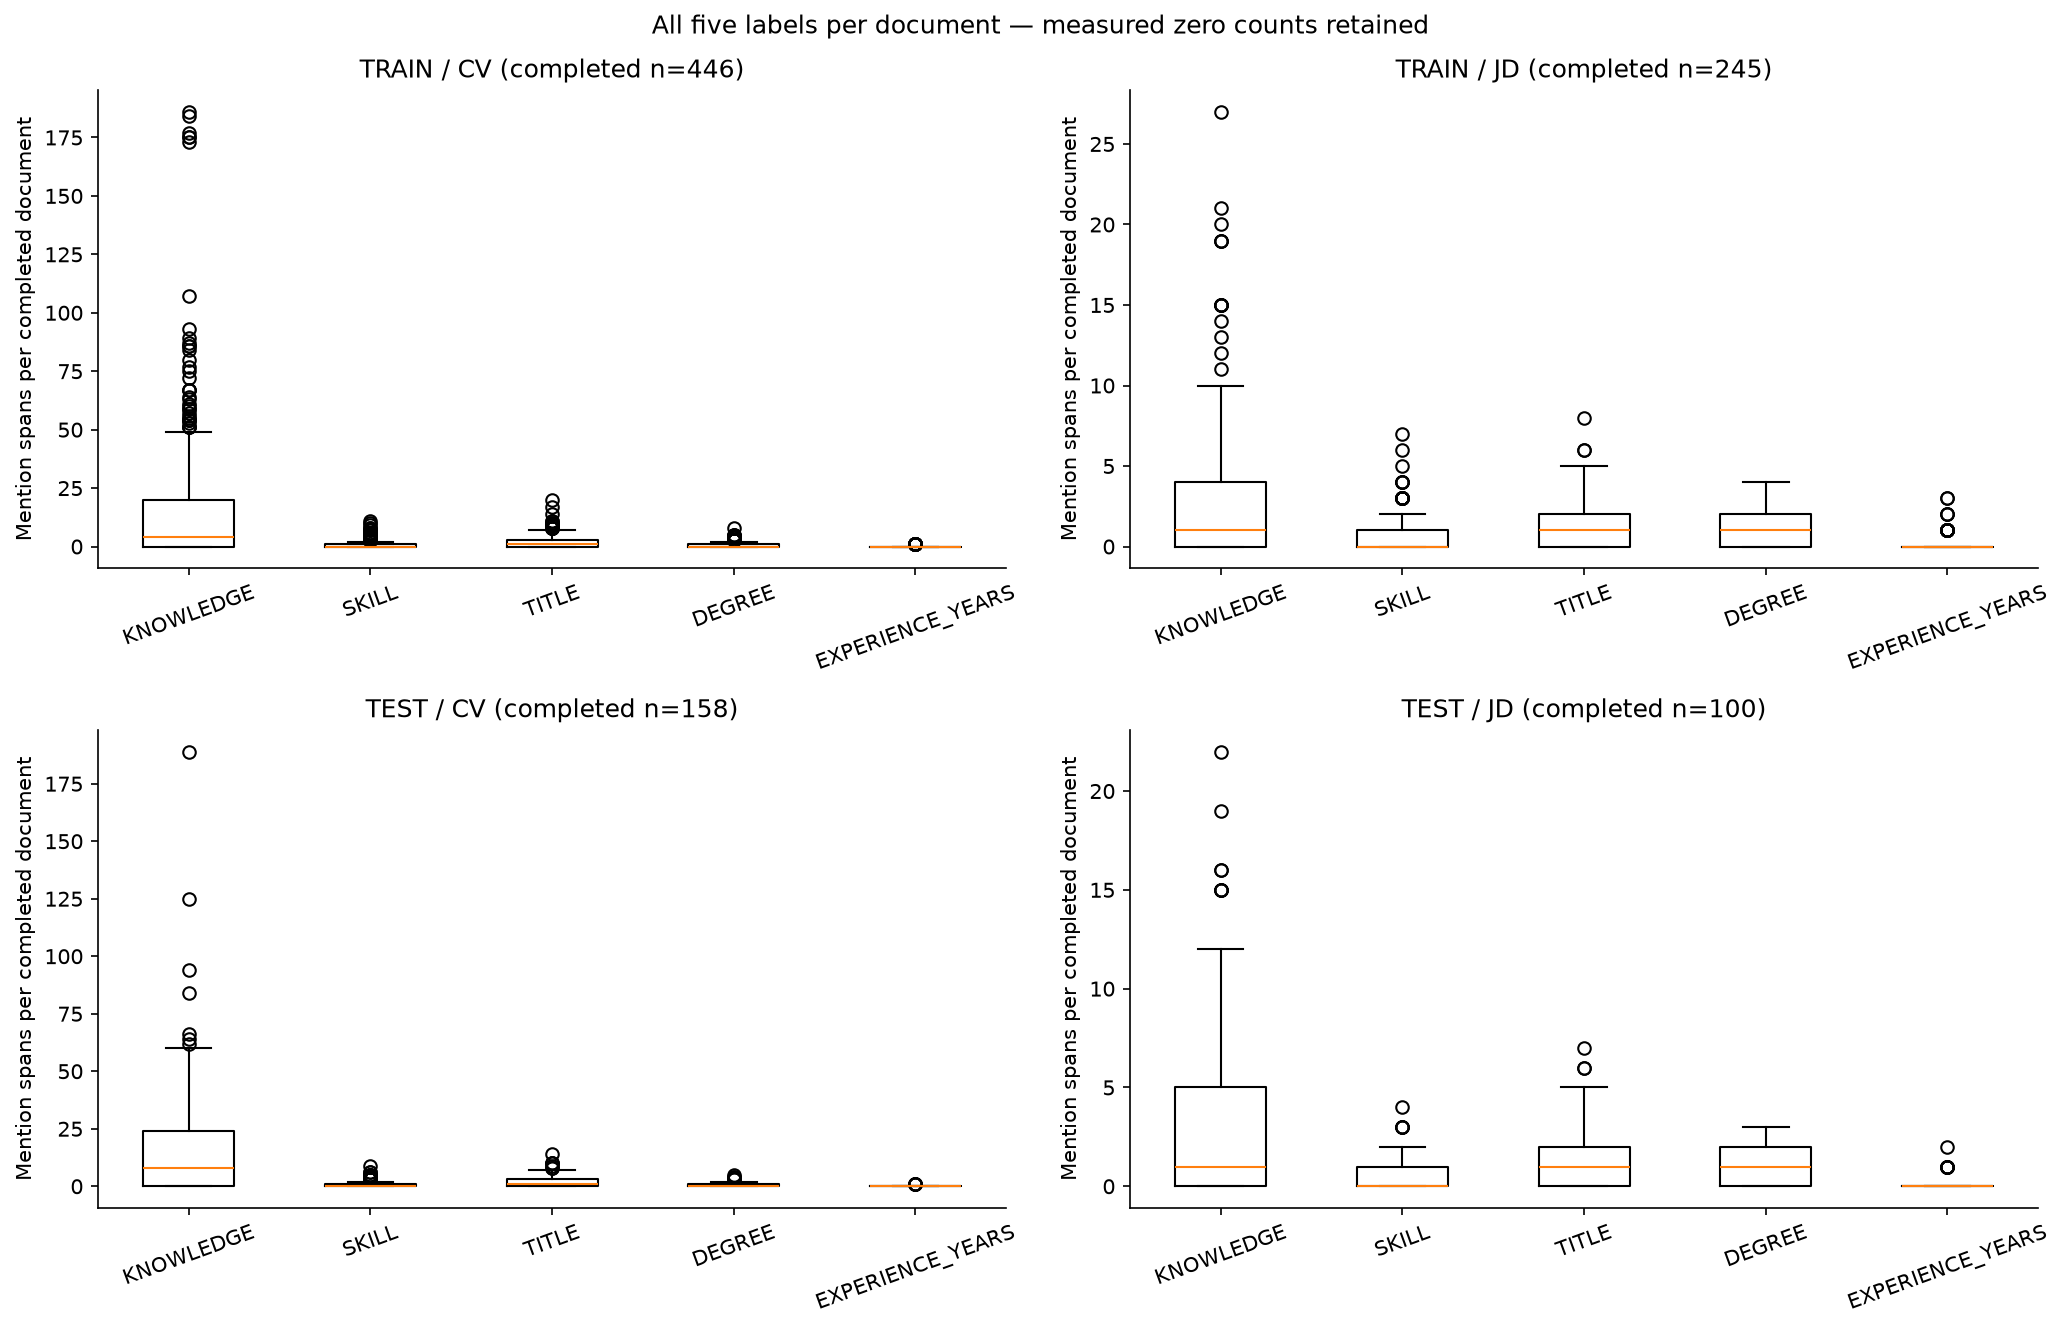

In [45]:
display(Image(filename=charts["distribution"]))

## Raw model scores

Scores are uncalibrated and conditional on the frozen extraction threshold of 0.5. They cannot be interpreted as proficiency, candidate fit or probability that the label is correct. No threshold search or model rerun occurs here.

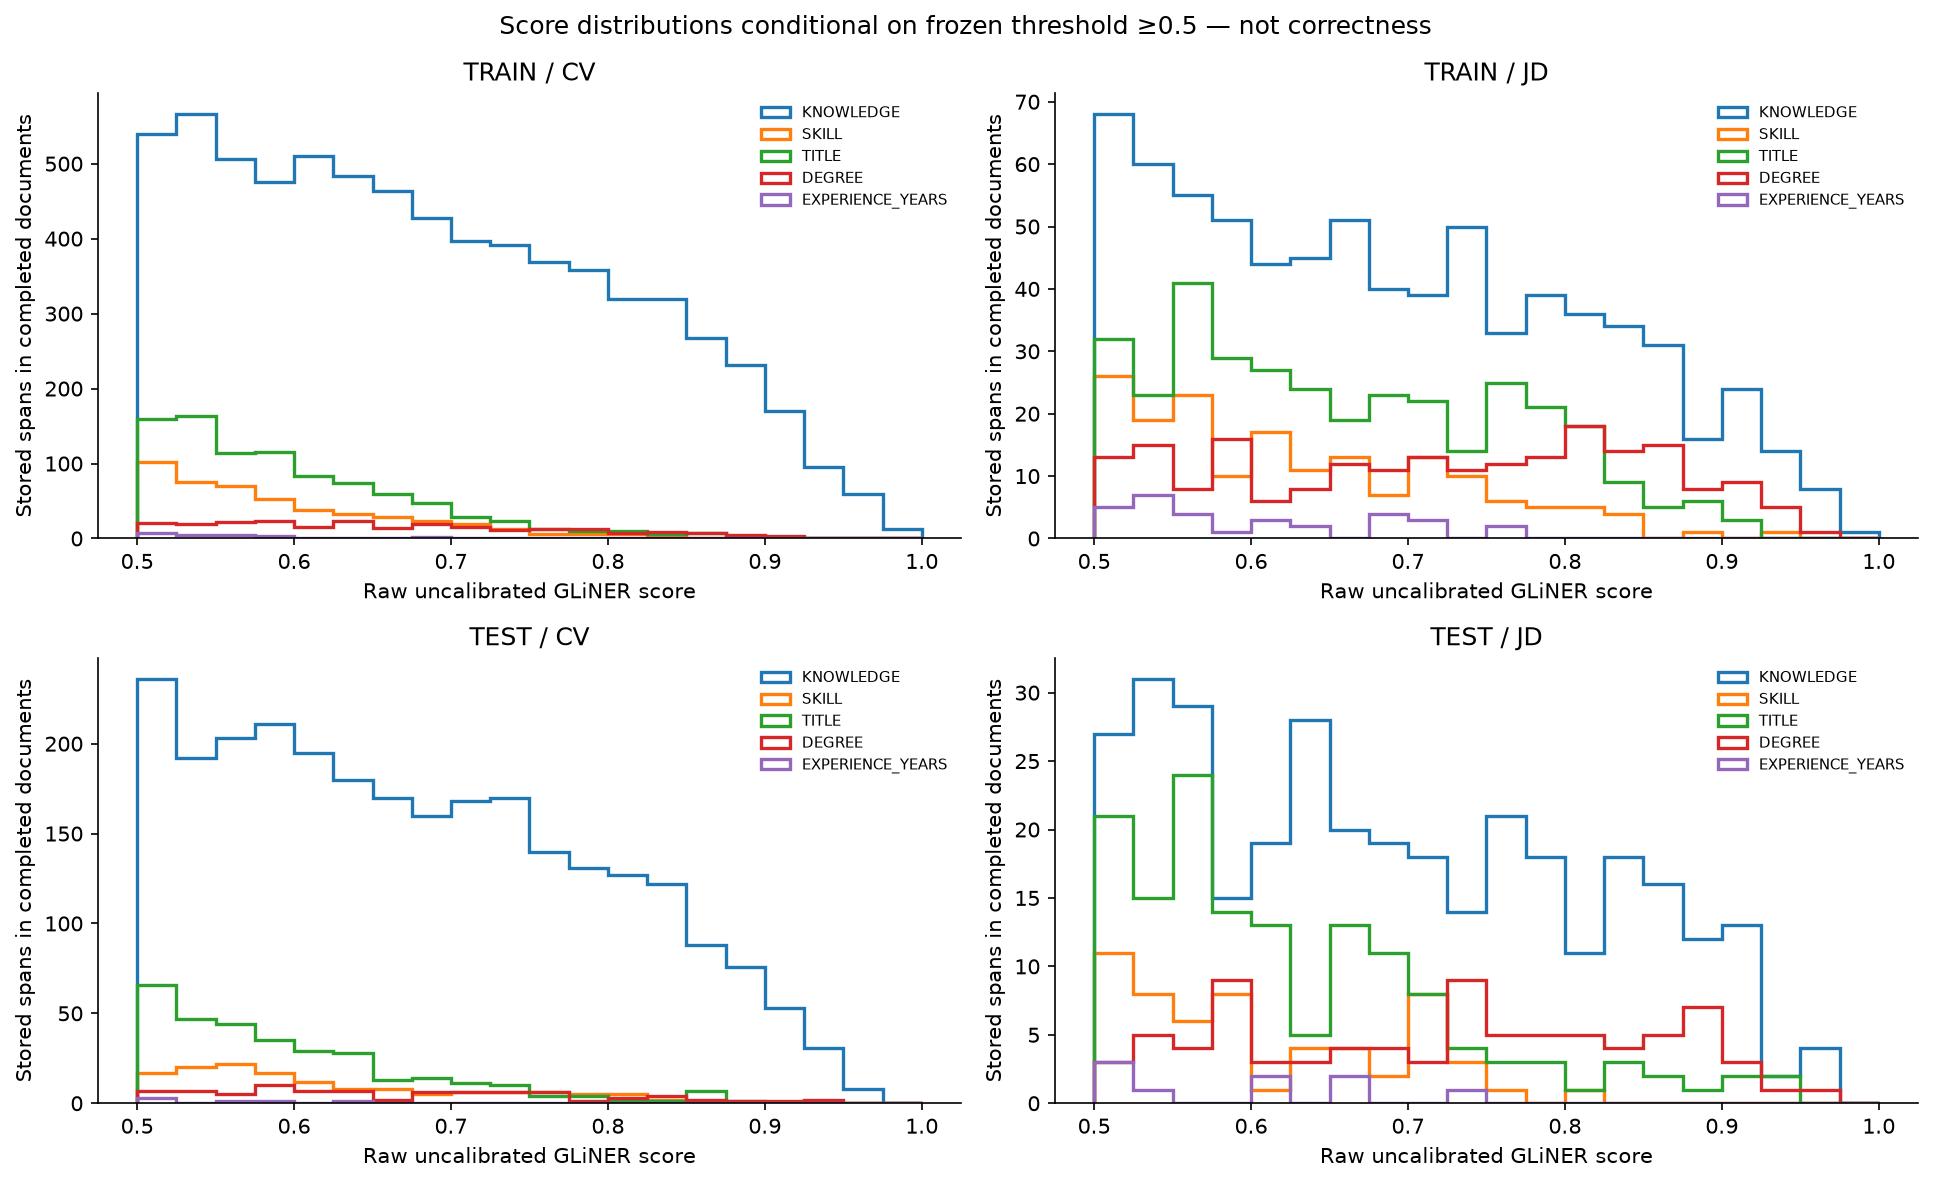

In [46]:
display(Image(filename=charts["scores"]))

## Pair-level extraction and exploratory Fit groups

The same extracted document can appear in multiple pairs, so pair-level counts and document-level counts answer different questions. Pair figures are not independent samples.

**A1 labels do not reproduce (A13).** Fit-conditioned summaries are exploratory and carry this limitation; they do not establish entity accuracy or screening success. No precision/recall/F1 is calculated from Fit labels.

In [47]:
preview = tables["pair_counts"]
assert len(preview) <= 5
print(preview.to_json(orient="records", force_ascii=False))


[{"split":"train","pairs":3990,"both_documents_complete":3990},{"split":"test","pairs":659,"both_documents_complete":659}]


### TRAIN / CV — exploratory A1 groups

**A1 labels do not reproduce (A13).** Each group uses the same both-documents-complete pair mask; counts include the all-pair denominator. These means do not measure extraction accuracy.

In [48]:
preview = tables["fit_conditioned"].loc[(tables["fit_conditioned"].split == "train") & (tables["fit_conditioned"].doc_type == "cv")]
rendered = preview.to_json(orient="records", force_ascii=False)
assert len(preview) <= 5 and len(rendered) <= 1990
print(rendered)


[{"split":"train","doc_type":"cv","fit_label":"Good Fit","pairs":953,"completed_document_pairs":953,"mean_entities_per_pair_document":26.8037775446,"limitation":"A1 labels do not reproduce (A13); descriptive only"},{"split":"train","doc_type":"cv","fit_label":"No Fit","pairs":1977,"completed_document_pairs":1977,"mean_entities_per_pair_document":22.5220030349,"limitation":"A1 labels do not reproduce (A13); descriptive only"},{"split":"train","doc_type":"cv","fit_label":"Potential Fit","pairs":1060,"completed_document_pairs":1060,"mean_entities_per_pair_document":22.258490566,"limitation":"A1 labels do not reproduce (A13); descriptive only"}]


### TRAIN / JD — exploratory A1 groups

**A1 labels do not reproduce (A13).** Each group uses the same both-documents-complete pair mask; counts include the all-pair denominator. These means do not measure extraction accuracy.

In [49]:
preview = tables["fit_conditioned"].loc[(tables["fit_conditioned"].split == "train") & (tables["fit_conditioned"].doc_type == "jd")]
rendered = preview.to_json(orient="records", force_ascii=False)
assert len(preview) <= 5 and len(rendered) <= 1990
print(rendered)


[{"split":"train","doc_type":"jd","fit_label":"Good Fit","pairs":953,"completed_document_pairs":953,"mean_entities_per_pair_document":7.1280167891,"limitation":"A1 labels do not reproduce (A13); descriptive only"},{"split":"train","doc_type":"jd","fit_label":"No Fit","pairs":1977,"completed_document_pairs":1977,"mean_entities_per_pair_document":6.9494183106,"limitation":"A1 labels do not reproduce (A13); descriptive only"},{"split":"train","doc_type":"jd","fit_label":"Potential Fit","pairs":1060,"completed_document_pairs":1060,"mean_entities_per_pair_document":6.7113207547,"limitation":"A1 labels do not reproduce (A13); descriptive only"}]


### TEST / CV — exploratory A1 groups

**A1 labels do not reproduce (A13).** Each group uses the same both-documents-complete pair mask; counts include the all-pair denominator. These means do not measure extraction accuracy.

In [50]:
preview = tables["fit_conditioned"].loc[(tables["fit_conditioned"].split == "test") & (tables["fit_conditioned"].doc_type == "cv")]
rendered = preview.to_json(orient="records", force_ascii=False)
assert len(preview) <= 5 and len(rendered) <= 1990
print(rendered)


[{"split":"test","doc_type":"cv","fit_label":"Good Fit","pairs":182,"completed_document_pairs":182,"mean_entities_per_pair_document":26.521978022,"limitation":"A1 labels do not reproduce (A13); descriptive only"},{"split":"test","doc_type":"cv","fit_label":"No Fit","pairs":344,"completed_document_pairs":344,"mean_entities_per_pair_document":22.523255814,"limitation":"A1 labels do not reproduce (A13); descriptive only"},{"split":"test","doc_type":"cv","fit_label":"Potential Fit","pairs":133,"completed_document_pairs":133,"mean_entities_per_pair_document":23.6766917293,"limitation":"A1 labels do not reproduce (A13); descriptive only"}]


### TEST / JD — exploratory A1 groups

**A1 labels do not reproduce (A13).** Each group uses the same both-documents-complete pair mask; counts include the all-pair denominator. These means do not measure extraction accuracy.

In [51]:
preview = tables["fit_conditioned"].loc[(tables["fit_conditioned"].split == "test") & (tables["fit_conditioned"].doc_type == "jd")]
rendered = preview.to_json(orient="records", force_ascii=False)
assert len(preview) <= 5 and len(rendered) <= 1990
print(rendered)


[{"split":"test","doc_type":"jd","fit_label":"Good Fit","pairs":182,"completed_document_pairs":182,"mean_entities_per_pair_document":8.1318681319,"limitation":"A1 labels do not reproduce (A13); descriptive only"},{"split":"test","doc_type":"jd","fit_label":"No Fit","pairs":344,"completed_document_pairs":344,"mean_entities_per_pair_document":6.9593023256,"limitation":"A1 labels do not reproduce (A13); descriptive only"},{"split":"test","doc_type":"jd","fit_label":"Potential Fit","pairs":133,"completed_document_pairs":133,"mean_entities_per_pair_document":6.4360902256,"limitation":"A1 labels do not reproduce (A13); descriptive only"}]


## Earlier CV/JD example

Inspect the earlier pair `r_006c891d237a` / `j_3acb4cc033cc`. The earlier bounded example reported 15 CV spans and zero JD spans under limited provenance; it is not strict replay gold. The full frozen campaign's counts and states below determine the current comparison.

Real surfaces and short context are contact-redacted before display. Original offsets continue to refer to the original local field, not the display string. No full resume or JD is printed.

In [52]:
EXAMPLE_CV = "r_006c891d237a"
EXAMPLE_JD = "j_3acb4cc033cc"
show_summary(example_counts(campaign, EXAMPLE_CV, EXAMPLE_JD))


[
  {
    "doc_type": "cv",
    "status": "complete",
    "current_spans": 15,
    "by_label": {
      "KNOWLEDGE": 4,
      "SKILL": 1,
      "TITLE": 9,
      "DEGREE": 1,
      "EXPERIENCE_YEARS": 0
    },
    "earlier_limited_example_spans": 15
  },
  {
    "doc_type": "jd",
    "status": "complete_zero",
    "current_spans": 0,
    "by_label": {
      "KNOWLEDGE": 0,
      "SKILL": 0,
      "TITLE": 0,
      "DEGREE": 0,
      "EXPERIENCE_YEARS": 0
    },
    "earlier_limited_example_spans": 0
  }
]


### Five-label string overlap for this pair

Shared and one-sided counts use case-folded mention strings, not canonical equivalence, a fitted match score or accuracy. Unfinished sides leave overlap unavailable.

In [53]:
preview = pair_mentions(campaign, EXAMPLE_CV, EXAMPLE_JD)
rendered = preview.to_json(orient="records", force_ascii=False)
assert len(preview) <= 5 and len(rendered) <= 1990
print(rendered)


[{"label":"KNOWLEDGE","cv_state":"complete","jd_state":"complete_zero","cv_unique_strings":2,"jd_unique_strings":0,"shared_strings":0,"cv_only_strings":2,"jd_only_strings":0},{"label":"SKILL","cv_state":"complete","jd_state":"complete_zero","cv_unique_strings":1,"jd_unique_strings":0,"shared_strings":0,"cv_only_strings":1,"jd_only_strings":0},{"label":"TITLE","cv_state":"complete","jd_state":"complete_zero","cv_unique_strings":9,"jd_unique_strings":0,"shared_strings":0,"cv_only_strings":9,"jd_only_strings":0},{"label":"DEGREE","cv_state":"complete","jd_state":"complete_zero","cv_unique_strings":1,"jd_unique_strings":0,"shared_strings":0,"cv_only_strings":1,"jd_only_strings":0},{"label":"EXPERIENCE_YEARS","cv_state":"complete","jd_state":"complete_zero","cv_unique_strings":0,"jd_unique_strings":0,"shared_strings":0,"cv_only_strings":0,"jd_only_strings":0}]


### Earlier example CV evidence

In [54]:
preview = examples(campaign, side="cv", doc_id=EXAMPLE_CV, limit=3)
preview["surface"] = preview["surface"].map(redact_text)
preview["context"] = preview["context"].map(redact_text)
assert_clean(preview["surface"], "fit example surfaces")
assert_clean(preview["context"], "fit bounded example context")
rendered = preview.to_json(orient="records", force_ascii=False)
assert len(preview) <= 5 and len(rendered) <= 1990
print(rendered)


[{"surface":"A \/CNA certification","label":"DEGREE","score":0.5055565834,"doc_type":"cv","field":"text","start":11103,"end":11123,"context":"sk ticket and phone support queue.\nEducation:A \/CNA certification,Expected in1997-Training Technologies-Rancho"},{"surface":"UNIX","label":"KNOWLEDGE","score":0.5643103123,"doc_type":"cv","field":"text","start":8075,"end":8079,"context":"eet SOP and SLA's, which ranged from windows\/UNIX server issues and everything in between.This"},{"surface":"UNIX","label":"KNOWLEDGE","score":0.561362505,"doc_type":"cv","field":"text","start":8172,"end":8176,"context":"volved: Windows XP and Server 2000 and 2003, UNIX 9, 10 and Linux on HP, Compaq, Dell and Sun "}]


### Earlier example JD evidence

In [55]:
preview = examples(campaign, side="jd", doc_id=EXAMPLE_JD, limit=3)
preview["surface"] = preview["surface"].map(redact_text)
preview["context"] = preview["context"].map(redact_text)
assert_clean(preview["surface"], "fit example surfaces")
assert_clean(preview["context"], "fit bounded example context")
rendered = preview.to_json(orient="records", force_ascii=False)
assert len(preview) <= 5 and len(rendered) <= 1990
print(rendered)


[]


## Limits

Operational integrity establishes source traceability, completion and reproducible configuration. A correct source slice can still receive the wrong semantic label, and absent predictions can still be missed entities. Entity accuracy requires compatible labelled spans; A1 Fit labels cannot provide those.

These exploratory train/test comparisons do not tune any model or threshold, change the research winner or establish a downstream matching improvement. Any future screening evaluation must follow the final-set protocol and report both strata beside total results.

ß